# Lumen-Aware Calibration on the Group Base Model (DAv2 Small + Smooth Correction)

**Base model (same as the group):** Depth Anything V2 Small + smooth depth-dependent correction, imported from
`results/E/refinement/smooth_model.py` (official DAv2 code, `infer_image(input_size=518)`):
- linear calibration: depth = clip(−scale · pred + offset, 1e-3, 100)
- smooth correction: depth = clip(depth + interp(depth, [10, 30, 50, 70], corrections), 1e-3, 100)

**Aim:** test if a correction that knows where the dark, far lumen is can improve the group base depth *D0*.
Each method corrects *D0*; no method replaces the base.

## Methods
| # | Method | Depth |
|---|---|---|
| 0 | Base: Small + smooth (group) | D0 = apply_smooth(pred, params) |
| 1 | + lumen-aware residual (darkness) | D0 + (1 − w) · r_wall(D0) + w · r_lumen(D0), cue = darkness |
| 2 | + lumen-aware residual (depth) | same, cue = far (rank of −pred) |
| 3 | + lumen-aware residual (both) | same, cue = √(dark · far) |
| 4 | + isotonic (log) | exp(f(D0)), f = isotonic fit of log(GT) on D0 |
| 5 | + lumen-aware isotonic (log) | exp((1 − w) · f_wall(D0) + w · f_lumen(D0)), cue = both |

The residual curves r are the mean signed error (GT − D0) in bins of D0 ([0, 20, 40, 60, 80, 100] mm, centres 10…90 mm),
weighted by 1 − w (wall) or w (lumen). A bin with a weighted count < 2000 gets a correction of 0.
The lumen map *w* uses no ground truth (same detector as `Final_Lumen_model.ipynb`).

## Protocol
- **Dev (trans_t1_a, 61 frames):** 4-block CV with a 2-frame gap (`common.dev_folds`). In each fold the base is
  also refitted with `smooth_model.fit_params` on the fit frames only; then methods 1–5 are fitted on the same frames.
- **Test (trans_t2_b, 103 frames):** base = frozen group parameters (`load_final_params()`); methods 1–5 fitted on all
  61 dev frames. Run **once**, in its own cell, only when `RUN_TEST = True`.
- Masks: **A** = 0 < raw < 65535 and RGB max > 10 (main); **B** = raw > 0 (keeps the clipped 100 mm pixels).
- Metrics (`common.compute_metrics` / `common.aggregate`): AbsRel, RMSE, MAE (mm), δ < 1.25; also AbsRel in the
  wall (w ≤ 0.5) and in the lumen (w > 0.5).

## 1. Settings
`RUN_TEST` is the only switch. Keep it `False` until all dev work is final; the test cell (Section 9) refuses to run
otherwise, and refuses to run a second time once `test_done.json` exists.

In [1]:
RUN_TEST = False                    # set to True only for the single final test run (Section 9)

import sys; sys.path.insert(0, "..")
from common import (CFG, DEVICE, SEED, DEPTH_MAX_MM, REPO_ROOT, list_frames, make_mask, compute_metrics,
                    aggregate, dev_folds, save_run_info, save_summary, stream_results_dir)

import json
from datetime import datetime

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm
from scipy import ndimage
from sklearn.isotonic import IsotonicRegression
from tqdm import tqdm

# ---- Settings ----
RUN_NAME   = "LumenAware_on_SmallSmooth"
INPUT_SIZE = 518                                     # same as the group model
DMAX       = DEPTH_MAX_MM                            # 100 mm
BIN_EDGES  = np.array([0, 20, 40, 60, 80, 100], dtype=np.float64)
CENTERS    = (BIN_EDGES[:-1] + BIN_EDGES[1:]) / 2    # 10, 30, 50, 70, 90 mm
MIN_PIXELS = 2000                                    # minimum weighted pixels in a residual bin
FIT_STRIDE = 4                                       # residual curves: every 4th mask-A pixel
ISO_STRIDE = 16                                      # isotonic fits: every 16th mask-A pixel
N_BLOCKS, GAP = 4, 2                                 # block CV (common.dev_folds)
CUES       = ["dark", "far", "both"]
SIGMA, TAU = 20, 0.5                                 # lumen detector (fixed, not fitted)
MASKS      = ["A", "B"]

out_dir   = stream_results_dir(CFG, RUN_NAME)        # results/LumenAware_on_SmallSmooth
fig_dir   = out_dir / "figures"
fig_dir.mkdir(exist_ok=True)
TEST_DONE = out_dir / "test_done.json"
CACHE     = REPO_ROOT / "results" / "E" / "refinement" / "cache"    # shared DAv2 Small predictions
dev_paths  = list_frames(CFG, "dev")                 # trans_t1_a
test_paths = list_frames(CFG, "test")                # trans_t2_b

# ---- Methods: (label, kind, cue) ----
BASE, FINAL = "Base: Small + smooth (group)", "+ lumen-aware isotonic (log)"
METHODS = [
    (BASE,                                "base",      None),
    ("+ lumen-aware residual (darkness)", "resid",     "dark"),
    ("+ lumen-aware residual (depth)",    "resid",     "far"),
    ("+ lumen-aware residual (both)",     "resid",     "both"),
    ("+ isotonic (log)",                  "iso",       None),
    (FINAL,                               "iso_lumen", "both"),
]
LABELS = [m[0] for m in METHODS]
COLORS = dict(zip(LABELS, ["#e0a030", "#a9cdb4", "#6aa486", "#2e6f4e", "#9467bd", "#4b2a7b"]))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(f"{len(dev_paths)} dev frames | {len(test_paths)} test frames | device {DEVICE} | RUN_TEST {RUN_TEST}")

61 dev frames | 103 test frames | device mps | RUN_TEST False


## 2. Group base model
Import the group model from `smooth_model.py` (not copied). Its `FINAL_PARAMS` path points to
`results/Depth Anything V2/`; the folder may also be named `results/DAv2`, so we point it to whichever exists.

In [2]:
sys.path.insert(0, str(REPO_ROOT / "results" / "E" / "refinement"))
import smooth_model
from smooth_model import DA2Small, apply_smooth, fit_params, load_final_params

for folder in ["DAv2", "Depth Anything V2"]:
    p = REPO_ROOT / "results" / folder / "final_model_parameters.json"
    if p.exists():
        smooth_model.FINAL_PARAMS = p
        break
else:
    raise FileNotFoundError("final_model_parameters.json not found in results/DAv2 or results/Depth Anything V2")

FROZEN = load_final_params()
print(f"Frozen group parameters ({smooth_model.FINAL_PARAMS.relative_to(REPO_ROOT)}):")
print(f"  scale {FROZEN['scale']:.4f}, offset {FROZEN['offset']:.4f}, "
      f"corrections at {FROZEN['centers'].tolist()} mm = {np.round(FROZEN['corrections'], 3).tolist()}")

Frozen group parameters (results/DAv2/final_model_parameters.json):
  scale 14.8027, offset 69.5310, corrections at [10.0, 30.0, 50.0, 70.0] mm = [1.852, -5.17, -5.013, 20.718]


## 3. Lumen detector (no ground truth)
Same as `Final_Lumen_model.ipynb`: Gaussian blur σ = 20 px, normalised for the field of view (RGB max > 10).
dark = 1 − clip(v_s / p99(v_s)); far = blurred rank of −pred; keep the largest region above τ = 0.5,
blur it again and normalise to max 1.

In [3]:
def blur(x, sigma=SIGMA):
    return cv2.GaussianBlur(x.astype(np.float32), (0, 0), sigma)


def lumen_cues(rgb, depth_like, fov, sigma=SIGMA):
    """Darkness and depth cues in [0, 1]. depth_like: a larger value = farther."""
    f = fov.astype(np.float32)
    v = rgb.astype(np.float32).max(axis=2) / 255.0
    v_s = blur(v * f, sigma) / (blur(f, sigma) + 1e-6)          # no darkening at the black corners
    dark = 1.0 - np.clip(v_s / (np.percentile(v_s[fov], 99) + 1e-6), 0, 1)
    far = np.zeros_like(v_s)
    ranks = depth_like[fov].argsort().argsort()
    far[fov] = ranks / max(len(ranks) - 1, 1)
    far = blur(far * f, sigma) / (blur(f, sigma) + 1e-6)
    dark[~fov], far[~fov] = 0, 0
    return dark, far


def combine(dark, far, cue):
    return {"dark": dark, "far": far}.get(cue, np.sqrt(dark * far))


def lumen_from_score(score, fov, sigma=SIGMA, tau=TAU):
    """Soft lumen map w and the hard core (largest region above tau)."""
    mask = (score > tau) & fov
    lab, n = ndimage.label(mask)
    if n == 0:
        return np.zeros(score.shape, np.float16), np.zeros(score.shape, bool)
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    core = lab == (np.argmax(sizes) + 1)
    w = blur(core * score, sigma)
    w = w / (w.max() + 1e-6)
    w[~fov] = 0
    return w.astype(np.float16), core


def make_lumen_maps(F):
    dark, far = lumen_cues(F["rgb"], -F["pred"], F["fov"])
    F["w"] = {}
    for cue in CUES:
        F["w"][cue], core = lumen_from_score(combine(dark, far, cue), F["fov"])
        if cue == "both":
            F["core"] = core

## 4. Load frames and DAv2 Small predictions
Predictions are read from `results/E/refinement/cache/<split>/<frame>_id.npy` (the group's cache).
A missing file is predicted once with `DA2Small()(bgr, 518)` and saved there.

In [4]:
def load_frames(paths, split):
    model, out = None, []
    for cp in tqdm(paths, desc=f"{split} frames"):
        bgr = cv2.imread(str(cp))
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        raw = tifffile.imread(cp.with_name(cp.name.replace("_color.png", "_depth.tiff")))
        stem = cp.stem.split("_")[0]
        f = CACHE / split / f"{stem}_id.npy"
        if f.exists():
            pred = np.load(f).astype(np.float32)
        else:
            model = model or DA2Small()
            pred = model(bgr, INPUT_SIZE)
            f.parent.mkdir(parents=True, exist_ok=True)
            np.save(f, pred.astype(np.float32))
        F = {"name": stem, "rgb": rgb, "raw": raw, "pred": pred,
             "gt": raw.astype(np.float32) / 65535.0 * DMAX,
             "fov": rgb.max(axis=2) > 10,
             "clipped": (raw == 65535) & (rgb.max(axis=2) > 10),
             "mask": {m: make_mask(raw, rgb, m) for m in MASKS}}
        make_lumen_maps(F)
        out.append(F)
    return out


FR = load_frames(dev_paths, "dev")                   # the test frames are loaded only in Section 9
print(f"Loaded {len(FR)} dev frames. Mean mask-A pixels: {np.mean([F['mask']['A'].mean() for F in FR]) * 100:.1f}%, "
      f"mask-B pixels: {np.mean([F['mask']['B'].mean() for F in FR]) * 100:.1f}%")

dev frames:   0%|          | 0/61 [00:00<?, ?it/s]

xFormers not available


xFormers not available


dev frames:   2%|▏         | 1/61 [00:02<02:22,  2.38s/it]

dev frames:   3%|▎         | 2/61 [00:02<01:13,  1.25s/it]

...

dev frames:  97%|█████████▋| 59/61 [00:28<00:00,  2.25it/s]

dev frames:  98%|█████████▊| 60/61 [00:28<00:00,  2.25it/s]

dev frames: 100%|██████████| 61/61 [00:29<00:00,  2.25it/s]

dev frames: 100%|██████████| 61/61 [00:29<00:00,  2.09it/s]

Loaded 61 dev frames. Mean mask-A pixels: 91.0%, mask-B pixels: 93.0%


## 5. Fitting and prediction
`fit_all(ids, base)` fits methods 1–5 on top of a given base (`D0 = apply_smooth(pred, base)`) on the frames in `ids`,
using mask-A pixels only. `predict` returns the depth of one method for one frame.

In [5]:
def fit_all(ids, base):
    d0s, errs, logs, ws = [], [], [], {c: [] for c in CUES}
    di, li, wi = [], [], []
    for i in ids:
        F, m = FR[i], FR[i]["mask"]["A"]
        D0 = apply_smooth(F["pred"], base)[m]
        g = F["gt"][m]
        d0s.append(D0[::FIT_STRIDE]); errs.append((g - D0)[::FIT_STRIDE])
        for c in CUES:
            ws[c].append(F["w"][c][m][::FIT_STRIDE])
        di.append(D0[::ISO_STRIDE]); li.append(np.log(g[::ISO_STRIDE]))
        wi.append(F["w"]["both"][m][::ISO_STRIDE])
    d, e = np.concatenate(d0s).astype(np.float64), np.concatenate(errs).astype(np.float64)
    k = np.clip(np.digitize(d, BIN_EDGES) - 1, 0, len(CENTERS) - 1)

    P = {"base": base, "curves": {}, "counts": {}}
    for c in CUES:
        w = np.concatenate(ws[c]).astype(np.float64)
        for part, wt in [("wall", 1.0 - w), ("lumen", w)]:
            s = np.bincount(k, weights=e * wt, minlength=len(CENTERS))
            n = np.bincount(k, weights=wt, minlength=len(CENTERS))
            P["curves"][f"{part}_{c}"] = np.where(n >= MIN_PIXELS, s / np.maximum(n, 1e-9), 0.0)
            P["counts"][f"{part}_{c}"] = n

    x, t = np.concatenate(di).astype(np.float64), np.concatenate(li).astype(np.float64)
    w = np.concatenate(wi).astype(np.float64)
    iso = lambda wt: IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x, t, sample_weight=wt)
    P["iso"] = iso(np.ones_like(x))
    P["iso_wall"], P["iso_lumen"] = iso(1.0 - w + 1e-6), iso(w + 1e-6)
    return P


def predict(kind, F, P, cue=None, D0=None):
    D0 = apply_smooth(F["pred"], P["base"]) if D0 is None else D0
    if kind == "base":
        return D0
    if kind == "resid":
        w = F["w"][cue].astype(np.float32)
        corr = ((1 - w) * np.interp(D0, CENTERS, P["curves"][f"wall_{cue}"])
                + w * np.interp(D0, CENTERS, P["curves"][f"lumen_{cue}"]))
        return np.clip(D0 + corr, 1e-3, DMAX)
    flat = D0.ravel()
    if kind == "iso":
        t = P["iso"].predict(flat)
    else:
        wf = F["w"][cue].astype(np.float32).ravel()
        t = (1 - wf) * P["iso_wall"].predict(flat) + wf * P["iso_lumen"].predict(flat)
    return np.clip(np.exp(t).reshape(D0.shape), 1e-3, DMAX)


def region_absrel(pred, F, valid):
    return compute_metrics(pred, F["gt"], valid)["absrel"] if valid.sum() >= 100 else np.nan


def eval_frame(F, P, extra):
    """Metrics of every method under masks A and B, plus AbsRel in the wall (w <= 0.5) and the lumen (w > 0.5)."""
    D0 = apply_smooth(F["pred"], P["base"])
    lumen = F["w"]["both"].astype(np.float32) > 0.5
    rows = []
    for label, kind, cue in METHODS:
        pred = predict(kind, F, P, cue, D0)
        for m in MASKS:
            v = F["mask"][m]
            rows.append({**extra, "frame": F["name"], "method": label, "mask": m,
                         **compute_metrics(pred, F["gt"], v),
                         "absrel_wall": region_absrel(pred, F, v & ~lumen),
                         "absrel_lumen": region_absrel(pred, F, v & lumen)})
    return rows


def summarise(pf):
    """One row per (mask, method): common.aggregate + wall/lumen AbsRel (+ folds better than base, if CV)."""
    out = []
    for m in MASKS:
        sub = pf[pf["mask"] == m]
        if "fold" in sub:
            fold_ab = sub.groupby(["method", "fold"]).absrel.mean().unstack()
            better = fold_ab.lt(fold_ab.loc[BASE], axis=1).sum(axis=1)
        for label in LABELS:
            g = sub[sub.method == label]
            row = {"mask": m, "method": label, **aggregate(g),
                   "absrel_wall": g.absrel_wall.mean(), "absrel_lumen": g.absrel_lumen.mean()}
            if "fold" in sub:
                row["folds_better"] = np.nan if label == BASE else int(better[label])
            out.append(row)
    return pd.DataFrame(out)

## 6. Dev: 4-block cross-validation
In each fold the base is refitted with `smooth_model.fit_params` on the fit frames only, then methods 1–5 are fitted on
the same frames. All methods are evaluated on the held-out block.

In [6]:
FOLDS = dev_folds(len(FR), N_BLOCKS, GAP)
HELD = {i: k for k, (_, held) in enumerate(FOLDS) for i in held}     # fold that holds out each frame

FOLD_PARAMS, rows = [], []
for k, (fit_ids, held_ids) in enumerate(tqdm(FOLDS, desc="Folds")):
    base = fit_params([FR[i]["pred"] for i in fit_ids], [FR[i]["raw"] for i in fit_ids])
    P = fit_all(fit_ids, base)
    FOLD_PARAMS.append(P)
    for i in held_ids:
        rows += eval_frame(FR[i], P, {"idx": i, "fold": k + 1})

per_frame = pd.DataFrame(rows)
abl = summarise(per_frame)
per_frame.to_csv(out_dir / "per_frame_dev_cv.csv", index=False)
abl.to_csv(out_dir / "dev_cv_summary.csv", index=False)
for k, (fit_ids, held_ids) in enumerate(FOLDS):
    b = FOLD_PARAMS[k]["base"]
    print(f"Fold {k + 1}: fit {len(fit_ids)} frames, held-out {held_ids[0]}-{held_ids[-1]} | base scale {b['scale']:.3f}, "
          f"offset {b['offset']:.3f}, corrections {np.round(b['corrections'], 2).tolist()}")

Folds:   0%|          | 0/4 [00:00<?, ?it/s]

Folds:  25%|██▌       | 1/4 [00:12<00:37, 12.63s/it]

Folds:  50%|█████     | 2/4 [00:23<00:23, 11.60s/it]

Folds:  75%|███████▌  | 3/4 [00:34<00:11, 11.31s/it]

Folds: 100%|██████████| 4/4 [00:46<00:00, 11.49s/it]

Folds: 100%|██████████| 4/4 [00:46<00:00, 11.56s/it]

Fold 1: fit 43 frames, held-out 0-15 | base scale 15.127, offset 70.913, corrections [1.75, -5.16, -5.31, 18.2]
Fold 2: fit 42 frames, held-out 16-30 | base scale 15.203, offset 71.387, corrections [1.85, -4.95, -5.68, 17.5]
Fold 3: fit 42 frames, held-out 31-45 | base scale 14.429, offset 68.184, corrections [1.97, -5.27, -4.75, 22.72]
Fold 4: fit 44 frames, held-out 46-60 | base scale 14.582, offset 68.097, corrections [1.85, -5.21, -4.16, 23.53]


## 7. Dev results
Table 1 uses mask A (main table), Table 2 uses mask B. "Folds better than base" counts the folds where the mean
held-out AbsRel of the method is lower than that of the base.

In [7]:
COLS = {"method": "Method", "absrel": "AbsRel ↓", "rmse": "RMSE (mm) ↓", "mae": "MAE (mm) ↓",
        "delta1": "δ<1.25 ↑", "absrel_wall": "AbsRel wall ↓", "absrel_lumen": "AbsRel lumen ↓",
        "folds_better": f"Folds better than base (of {N_BLOCKS})"}
LOW  = ["AbsRel ↓", "RMSE (mm) ↓", "MAE (mm) ↓", "AbsRel wall ↓", "AbsRel lumen ↓"]


def show_table(df, title):
    d = df[[c for c in COLS if c in df]].rename(columns=COLS)
    fmt = ({c: "{:.3f}" for c in ["AbsRel ↓", "δ<1.25 ↑", "AbsRel wall ↓", "AbsRel lumen ↓"] if c in d} |
           {c: "{:.2f}" for c in ["RMSE (mm) ↓", "MAE (mm) ↓"] if c in d} |
           {c: "{:.0f}" for c in [COLS["folds_better"]] if c in d})
    styled = (d.style.format(fmt, na_rep="–")
              .highlight_min(subset=[c for c in LOW if c in d], props="font-weight: bold")
              .highlight_max(subset=[c for c in ["δ<1.25 ↑"] if c in d], props="font-weight: bold")
              .hide(axis="index").set_caption(title)
              .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold; text-align: left;"},
                                 {"selector": "th, td", "props": "padding: 4px 12px; text-align: left;"}]))
    display(styled)


for n, m in enumerate(MASKS, start=1):
    show_table(abl[abl["mask"] == m],
               f"Table {n}. Dev held-out results, {N_BLOCKS}-block CV on trans_t1_a ({len(FR)} frames), mask {m}")

A = abl[abl["mask"] == "A"].set_index("method")
for label in LABELS[1:]:
    print(f"{label:36s}: AbsRel {A.absrel[BASE]:.4f} -> {A.absrel[label]:.4f} "
          f"(gain {A.absrel[BASE] - A.absrel[label]:+.4f}), better in {A.folds_better[label]:.0f} of {N_BLOCKS} folds")

Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓,Folds better than base (of 4)
Base: Small + smooth (group),0.285,5.96,4.71,0.507,0.324,0.147,–
+ lumen-aware residual (darkness),0.267,5.38,4.24,0.543,0.307,0.121,4
+ lumen-aware residual (depth),0.273,5.74,4.48,0.527,0.311,0.140,3
+ lumen-aware residual (both),0.268,5.59,4.37,0.535,0.306,0.136,4
+ isotonic (log),0.241,5.59,4.21,0.571,0.270,0.138,4
+ lumen-aware isotonic (log),0.237,5.40,4.08,0.582,0.266,0.132,4


Method,AbsRel ↓,RMSE (mm) ↓,MAE (mm) ↓,δ<1.25 ↑,AbsRel wall ↓,AbsRel lumen ↓,Folds better than base (of 4)
Base: Small + smooth (group),0.282,6.39,4.96,0.514,0.324,0.148,–
+ lumen-aware residual (darkness),0.264,5.76,4.45,0.550,0.308,0.123,4
+ lumen-aware residual (depth),0.271,6.11,4.69,0.534,0.311,0.140,3
+ lumen-aware residual (both),0.266,5.97,4.58,0.542,0.306,0.136,4
+ isotonic (log),0.239,5.91,4.38,0.577,0.270,0.137,4
+ lumen-aware isotonic (log),0.234,5.73,4.26,0.588,0.266,0.131,4


+ lumen-aware residual (darkness)   : AbsRel 0.2848 -> 0.2666 (gain +0.0182), better in 4 of 4 folds
+ lumen-aware residual (depth)      : AbsRel 0.2848 -> 0.2734 (gain +0.0114), better in 3 of 4 folds
+ lumen-aware residual (both)       : AbsRel 0.2848 -> 0.2683 (gain +0.0165), better in 4 of 4 folds
+ isotonic (log)                    : AbsRel 0.2848 -> 0.2415 (gain +0.0433), better in 4 of 4 folds
+ lumen-aware isotonic (log)        : AbsRel 0.2848 -> 0.2369 (gain +0.0479), better in 4 of 4 folds


## 8. Figures (dev)
### 8.1 Methods 1–5 fitted on all 61 dev frames
These parameters, on top of the **frozen** group base, are the ones used for the test.
Figure 1 shows what they learn.

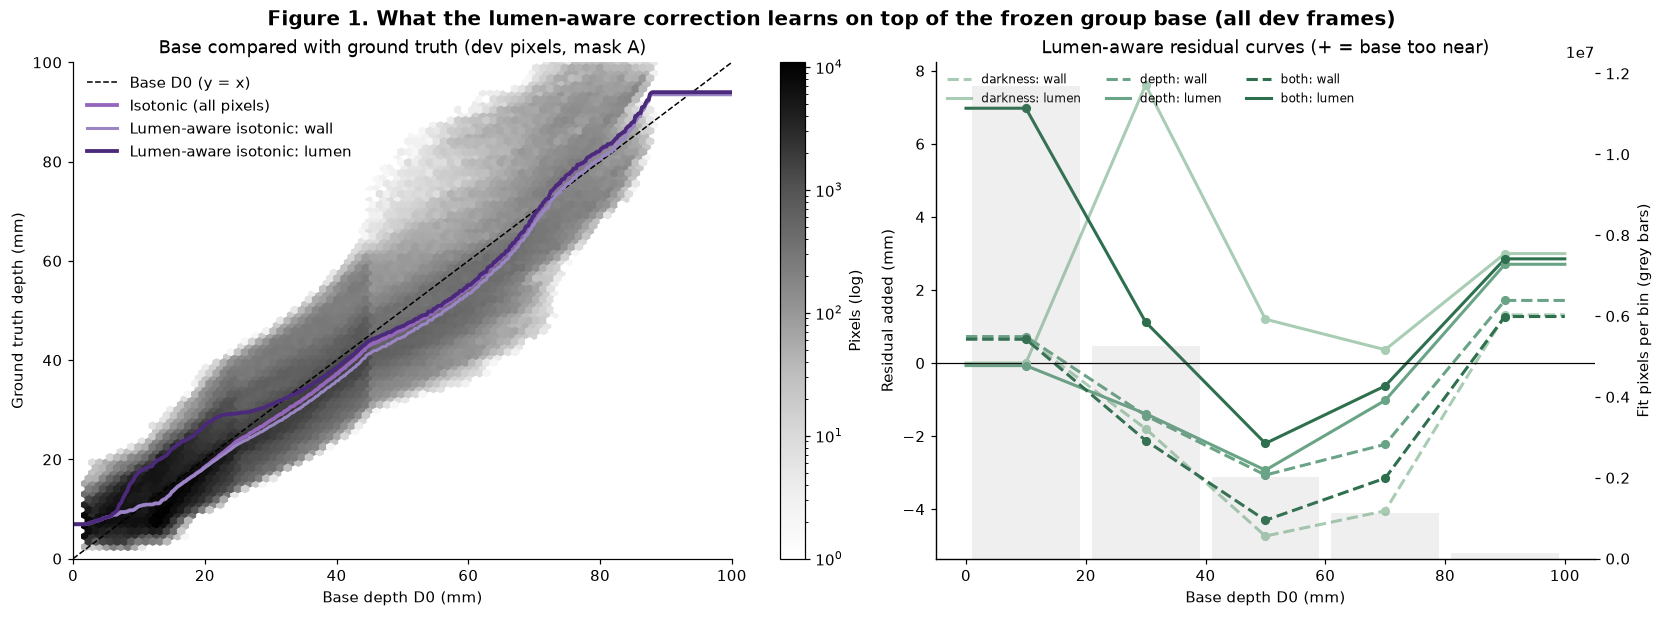

In [8]:
P_all = fit_all(list(range(len(FR))), FROZEN)

xs, ys = [], []
for F in FR:
    m = F["mask"]["A"]
    xs.append(apply_smooth(F["pred"], FROZEN)[m][::40]); ys.append(F["gt"][m][::40])
x, y = np.concatenate(xs), np.concatenate(ys)
g = np.linspace(0, DMAX, 500)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
hb = axes[0].hexbin(x, y, gridsize=80, bins="log", cmap="Greys", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="Pixels (log)")
axes[0].plot(g, g, "--", color="black", lw=1, label="Base D0 (y = x)")
axes[0].plot(g, np.exp(P_all["iso"].predict(g)), color=COLORS["+ isotonic (log)"], lw=2.5, label="Isotonic (all pixels)")
axes[0].plot(g, np.exp(P_all["iso_wall"].predict(g)), color="#9a86c4", lw=2, label="Lumen-aware isotonic: wall")
axes[0].plot(g, np.exp(P_all["iso_lumen"].predict(g)), color=COLORS[FINAL], lw=2.5, label="Lumen-aware isotonic: lumen")
axes[0].set(xlabel="Base depth D0 (mm)", ylabel="Ground truth depth (mm)", xlim=(0, DMAX), ylim=(0, DMAX),
            title="Base compared with ground truth (dev pixels, mask A)")
axes[0].legend(frameon=False, loc="upper left")

for c in CUES:
    label = next(l for l, k, cue in METHODS if k == "resid" and cue == c)
    for part, ls in [("wall", "--"), ("lumen", "-")]:
        cy = P_all["curves"][f"{part}_{c}"]
        axes[1].plot(g, np.interp(g, CENTERS, cy), ls, color=COLORS[label], lw=2, label=f"{label.split('(')[1][:-1]}: {part}")
        axes[1].scatter(CENTERS, cy, color=COLORS[label], s=25, zorder=3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="Base depth D0 (mm)", ylabel="Residual added (mm)",
            title="Lumen-aware residual curves (+ = base too near)")
ax2 = axes[1].twinx()
ax2.bar(CENTERS, P_all["counts"]["wall_both"] + P_all["counts"]["lumen_both"], width=18, alpha=0.12, color="grey")
ax2.set_ylabel("Fit pixels per bin (grey bars)"); ax2.spines["top"].set_visible(False)
axes[1].legend(frameon=False, loc="upper left", ncol=3, fontsize=8)
fig.suptitle("Figure 1. What the lumen-aware correction learns on top of the frozen group base (all dev frames)",
             fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "fig1_correction_curves.png", dpi=200, bbox_inches="tight"); plt.show()

### 8.2 Held-out AbsRel per fold
Figure 2 shows the mean held-out AbsRel (mask A) of each method in each fold.

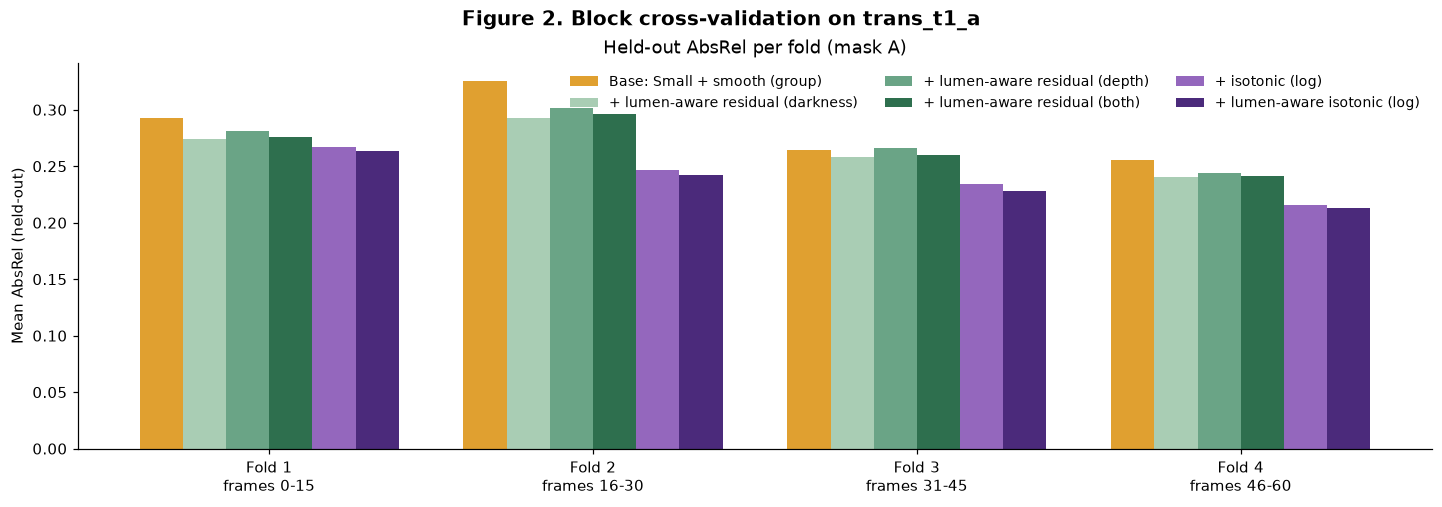

In [9]:
fold_ab = per_frame[per_frame["mask"] == "A"].groupby(["method", "fold"]).absrel.mean().unstack().loc[LABELS]
xf = np.arange(N_BLOCKS); wdt = 0.8 / len(LABELS)

fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
for j, label in enumerate(LABELS):
    ax.bar(xf + (j - (len(LABELS) - 1) / 2) * wdt, fold_ab.loc[label], wdt, color=COLORS[label], label=label)
ax.set_xticks(xf)
ax.set_xticklabels([f"Fold {k + 1}\nframes {h[0]}-{h[-1]}" for k, (_, h) in enumerate(FOLDS)])
ax.set(ylabel="Mean AbsRel (held-out)", title="Held-out AbsRel per fold (mask A)")
ax.legend(frameon=False, ncol=3, fontsize=9)
fig.suptitle("Figure 2. Block cross-validation on trans_t1_a", fontsize=13, fontweight="bold")
plt.savefig(fig_dir / "fig2_cv_folds.png", dpi=200, bbox_inches="tight"); plt.show()

### 8.3 Example frames
Figure 3 shows the best, median and worst held-out dev frames for the final method (mask A), each with the
parameters of the fold that held it out.

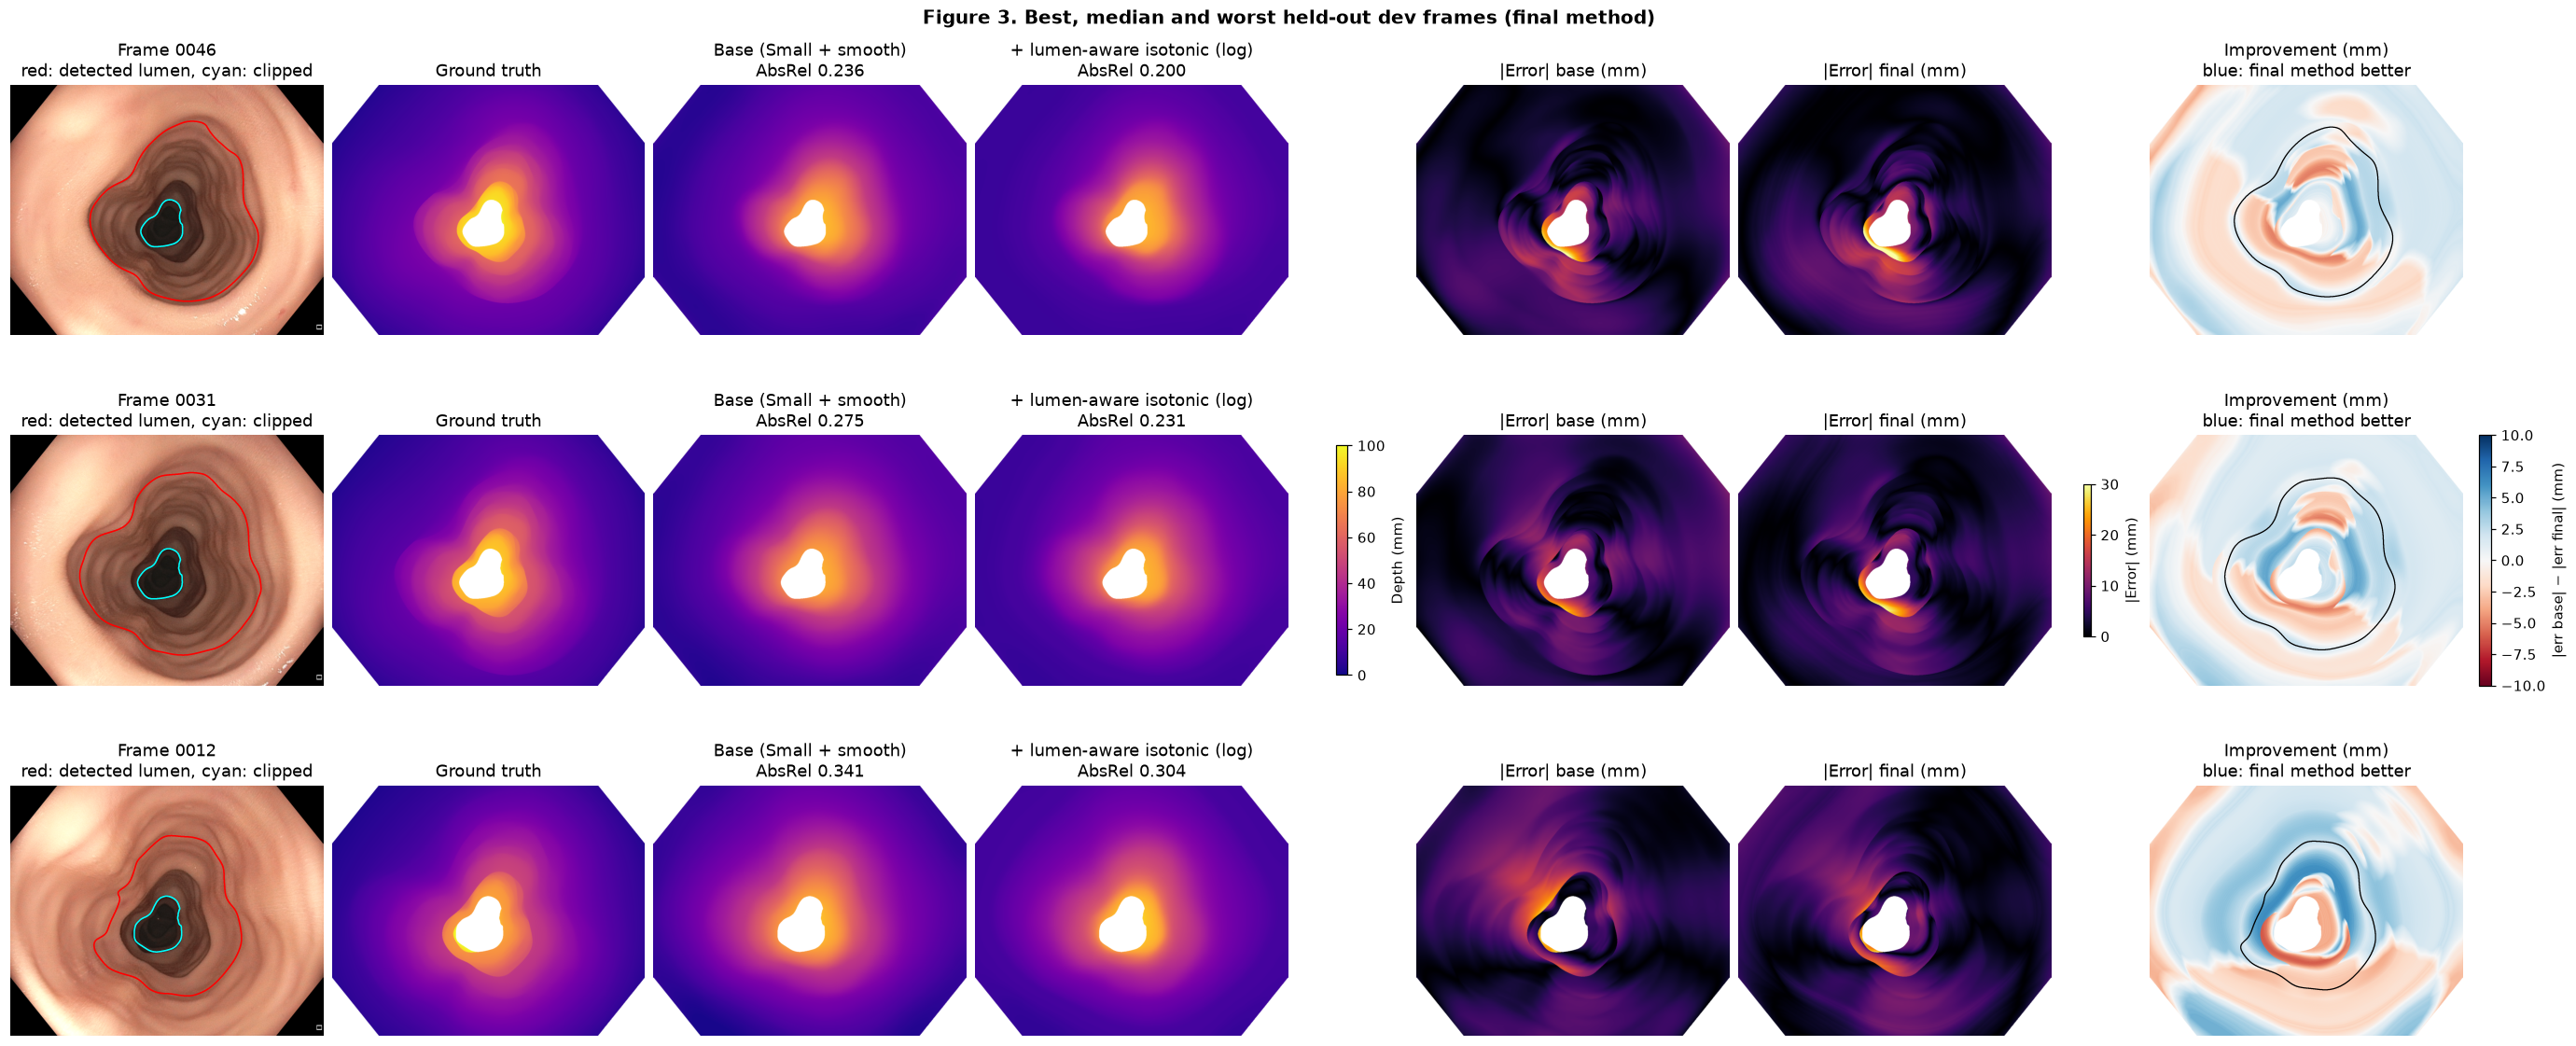

In [10]:
def nanv(a, F):
    return np.where(F["mask"]["A"], a, np.nan)


def fig_examples(frames, params, title, fname):
    fig, axes = plt.subplots(len(frames), 7, figsize=(25, 3.5 * len(frames)), constrained_layout=True)
    axes = np.atleast_2d(axes)
    for r, (F, P) in enumerate(zip(frames, params)):
        v = F["mask"]["A"]
        base, fin = predict("base", F, P), predict("iso_lumen", F, P, "both")
        es, ef = np.abs(base - F["gt"]), np.abs(fin - F["gt"])
        ax = axes[r]
        ax[0].imshow(F["rgb"])
        ax[0].contour(F["core"], colors="red", linewidths=1)
        ax[0].contour(F["clipped"], colors="cyan", linewidths=1)
        ax[0].set_title(f"Frame {F['name']}\nred: detected lumen, cyan: clipped")
        for j, (d, t) in enumerate([(F["gt"], "Ground truth"),
                                    (base, f"Base (Small + smooth)\nAbsRel {compute_metrics(base, F['gt'], v)['absrel']:.3f}"),
                                    (fin, f"{FINAL}\nAbsRel {compute_metrics(fin, F['gt'], v)['absrel']:.3f}")], start=1):
            im_d = ax[j].imshow(nanv(d, F), cmap="plasma", vmin=0, vmax=DMAX); ax[j].set_title(t)
        im_e = ax[4].imshow(nanv(es, F), cmap="inferno", vmin=0, vmax=30); ax[4].set_title("|Error| base (mm)")
        ax[5].imshow(nanv(ef, F), cmap="inferno", vmin=0, vmax=30); ax[5].set_title("|Error| final (mm)")
        im_i = ax[6].imshow(nanv(es - ef, F), cmap="RdBu", norm=TwoSlopeNorm(0, -10, 10))
        ax[6].contour(F["w"]["both"].astype(np.float32) > 0.5, colors="black", linewidths=0.8)
        ax[6].set_title("Improvement (mm)\nblue: final method better")
        for a in ax:
            a.axis("off")
    fig.colorbar(im_d, ax=axes[:, 1:4], fraction=0.012, label="Depth (mm)")
    fig.colorbar(im_e, ax=axes[:, 4:6], fraction=0.012, label="|Error| (mm)")
    fig.colorbar(im_i, ax=axes[:, 6], fraction=0.04, label="|err base| − |err final| (mm)")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.savefig(fig_dir / fname, dpi=200, bbox_inches="tight"); plt.show()


order = per_frame[(per_frame.method == FINAL) & (per_frame["mask"] == "A")].set_index("idx").absrel.sort_values()
pick = [order.index[0], order.index[len(order) // 2], order.index[-1]]
fig_examples([FR[i] for i in pick], [FOLD_PARAMS[HELD[i]] for i in pick],
             "Figure 3. Best, median and worst held-out dev frames (final method)", "fig3_dev_examples.png")

### 8.4 Save dev results
Saves the parameters fitted on all dev frames (used for the test), the group summary table and `run_info.json`.

In [11]:
iso_to_dict = lambda m: {"x": m.X_thresholds_.tolist(), "log_depth": m.y_thresholds_.tolist()}
base_to_dict = lambda b: {"scale": b["scale"], "offset": b["offset"], "centers": np.asarray(b["centers"]).tolist(),
                          "corrections": np.asarray(b["corrections"]).tolist()}
with open(out_dir / "params_dev.json", "w") as f:
    json.dump({"base_frozen": base_to_dict(FROZEN), "base_source": str(smooth_model.FINAL_PARAMS.relative_to(REPO_ROOT)),
               "base_per_fold": [base_to_dict(P["base"]) for P in FOLD_PARAMS],
               "sigma": SIGMA, "tau": TAU, "bin_edges": BIN_EDGES.tolist(), "centers": CENTERS.tolist(),
               "min_pixels": MIN_PIXELS, "fit_stride": FIT_STRIDE, "iso_stride": ISO_STRIDE,
               "curves_all_dev": {k: v.tolist() for k, v in P_all["curves"].items()},
               "isotonic_all_dev": {k: iso_to_dict(P_all[k]) for k in ["iso", "iso_wall", "iso_lumen"]}}, f, indent=2)


def group_rows(tab, split):
    return [{"model": f"DAv2 Small + smooth {r.method}" if r.method != BASE else "DAv2 Small + smooth (group base)",
             "output_type": "disparity", "alignment": "global_lsq + smooth",
             "fit_on": "dev_blocks_cv" if split == "dev" else "dev_all (base: frozen group params)",
             "split": split, "mask": r.mask, "n_frames": r.n_frames,
             "absrel": r.absrel, "rmse": r.rmse, "mae": r.mae, "delta1": r.delta1} for r in tab.itertuples()]


save_summary(group_rows(abl, "dev"), out_dir, RUN_NAME)
save_run_info(out_dir, DEVICE, SEED, extra={"base_model": "DAv2 Small + smooth (results/E/refinement/smooth_model.py)",
                                             "input_size": INPUT_SIZE, "sigma": SIGMA, "tau": TAU,
                                             "n_blocks": N_BLOCKS, "gap": GAP, "masks": MASKS})
print(f"Saved dev results to {out_dir}")

Saved dev results to /Users/aditiraghu/c3vd/results/LumenAware_on_SmallSmooth


## 9. Test (trans_t2_b) — run once
Base = frozen group parameters; methods 1–5 = `P_all` (fitted on all 61 dev frames). This cell stops if
`RUN_TEST` is False, and refuses to run if `test_done.json` already exists.

In [12]:
if not RUN_TEST:
    raise RuntimeError("RUN_TEST is False: the test was not run. Set RUN_TEST = True in Section 1 for the final run.")
if TEST_DONE.exists():
    raise RuntimeError(f"The test was already run ({TEST_DONE} exists). It is run only once.")

TE = load_frames(test_paths, "test")
test_rows = []
for F in TE:
    test_rows += eval_frame(F, P_all, {})
test_pf = pd.DataFrame(test_rows)
test_tab = summarise(test_pf)
test_pf.to_csv(out_dir / "per_frame_test.csv", index=False)
test_tab.to_csv(out_dir / "test_summary.csv", index=False)
save_summary(group_rows(abl, "dev") + group_rows(test_tab, "test"), out_dir, RUN_NAME)

for n, m in enumerate(MASKS, start=4):
    show_table(test_tab[test_tab["mask"] == m],
               f"Table {n}. Test results on trans_t2_b ({len(TE)} frames), mask {m}; frozen base, methods 1–5 fitted on all dev")
T = test_tab[test_tab["mask"] == "A"].set_index("method")
for label in LABELS[1:]:
    print(f"{label:36s}: AbsRel {T.absrel[BASE]:.4f} -> {T.absrel[label]:.4f} (gain {T.absrel[BASE] - T.absrel[label]:+.4f})")

with open(TEST_DONE, "w") as f:
    json.dump({"date": datetime.now().isoformat(timespec="seconds"), "n_frames": len(TE),
               "absrel_mask_A": T.absrel.to_dict()}, f, indent=2)
print(f"Test done. Saved to {out_dir}")

RuntimeError: RUN_TEST is False: the test was not run. Set RUN_TEST = True in Section 1 for the final run.

### 9.1 Test example frames
Figure 4 shows the best, median and worst test frames for the final method. It needs the test cell above to have run
in this session.

In [13]:
if "test_pf" not in globals():
    print("Run the test cell (Section 9) first.")
else:
    order_t = test_pf[(test_pf.method == FINAL) & (test_pf["mask"] == "A")].set_index("frame").absrel.sort_values()
    name_to_F = {F["name"]: F for F in TE}
    pick_t = [order_t.index[0], order_t.index[len(order_t) // 2], order_t.index[-1]]
    fig_examples([name_to_F[n] for n in pick_t], [P_all] * 3,
                 "Figure 4. Best, median and worst test frames (trans_t2_b)", "fig4_test_examples.png")

Run the test cell (Section 9) first.
